# RouteRanker – Milestone 3: Model Selection, Training and Inference

**Project:** AI-Powered Public Transit Route Optimization

**City:** New York, USA

**Transport Network:** New York MTA


## 1. Introduction

This milestone focuses on developing machine-learning models to analyze New York MTA bus routes. Clustering algorithms will group routes with similar scheduled service characteristics. Model evaluation and inference will help identify routes that may require further investigation and optimization.

## 2. Objectives

- Apply K-Means and DBSCAN clustering algorithms.
- Analyze similarities between bus routes.
- Evaluate clustering results.
- Explore route optimization recommendations.
- Prepare model outputs for future dashboard development.

## 3. Scope

This milestone initially uses the processed route-level GTFS features prepared during Milestone 2. These features describe scheduled service and route coverage, rather than actual passenger demand.

## 4. Expected Outcomes

- Trained clustering models.
- Route cluster assignments.
- Model evaluation results.
- Initial route optimization suggestions.
- Saved model outputs for future use.

## 5. Importing Required Libraries

This section imports the Python libraries required for machine-learning model development. Pandas and NumPy are used for data handling, Matplotlib and Seaborn for visualization, and Scikit-learn for implementing and evaluating clustering algorithms.

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All required libraries imported successfully!")

All required libraries imported successfully!


## 6. Loading Processed Training and Validation Datasets

This section loads the scaled training and validation datasets generated during Milestone 2. These datasets contain standardized route-level features that will be used to train and evaluate clustering algorithms.

In [ ]:
from google.colab import files
import pandas as pd

uploaded = {}

uploaded.update(files.upload())

Saving new_york_validation_scaled.csv to new_york_validation_scaled (2).csv


In [ ]:
from google.colab import files
import pandas as pd

uploaded = {}

uploaded.update(files.upload())

Saving new_york_train_scaled.csv to new_york_train_scaled.csv


In [ ]:
from google.colab import files

uploaded.update(files.upload())

Saving new_york_validation_scaled.csv to new_york_validation_scaled (3).csv


In [ ]:
print("Uploaded files:", list(uploaded.keys()))

Uploaded files: ['new_york_train_scaled.csv', 'new_york_validation_scaled (3).csv']


In [ ]:
# Load both uploaded datasets

import io

X_train = pd.read_csv(
    io.BytesIO(uploaded["new_york_train_scaled.csv"])
)

X_val = pd.read_csv(
    io.BytesIO(uploaded["new_york_validation_scaled (3).csv"])
)

print("Both datasets loaded successfully!")

print("Training Dataset Shape:", X_train.shape)
print("Validation Dataset Shape:", X_val.shape)

display(X_train.head())

Both datasets loaded successfully!
Training Dataset Shape: (23, 4)
Validation Dataset Shape: (6, 4)


,total_scheduled_trips,unique_stops,total_stop_time_records,average_stops_per_trip
0,2.309600,-0.559281,1.229073,-0.285726
1,0.971257,0.253760,1.389962,0.822095
2,-1.369469,-0.733504,-1.255006,-0.599037
3,0.568655,0.079537,0.034590,-0.338448
4,-1.355041,-1.720768,-1.465437,-1.927226


## 7. Dataset Structure Verification

This section verifies the structure of the training and validation datasets. It checks the number of records, available features, and consistency between both datasets before applying machine-learning algorithms.

In [ ]:
# Verify training and validation datasets

print("Training Dataset Shape:", X_train.shape)
print("Validation Dataset Shape:", X_val.shape)

print("\nTraining Columns:")
print(X_train.columns.tolist())

print("\nValidation Columns:")
print(X_val.columns.tolist())

print("\nAre both datasets using the same features?")
print(list(X_train.columns) == list(X_val.columns))

Training Dataset Shape: (23, 4)
Validation Dataset Shape: (6, 4)

Training Columns:
['total_scheduled_trips', 'unique_stops', 'total_stop_time_records', 'average_stops_per_trip']

Validation Columns:
['total_scheduled_trips', 'unique_stops', 'total_stop_time_records', 'average_stops_per_trip']

Are both datasets using the same features?
True


## 8. K-Means Clustering

K-Means is an unsupervised machine-learning algorithm that groups similar data points into a predefined number of clusters.

In RouteRanker, K-Means is used to group New York MTA bus routes based on their scheduled trips, unique stops, stop-time records, and average stops per trip.

The algorithm assigns each route to a cluster based on similarity between its numerical features.

In [ ]:
# Train the K-Means clustering model

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_train)

# Predict clusters for training and validation data
train_clusters = kmeans.predict(X_train)
val_clusters = kmeans.predict(X_val)

print("K-Means Model Trained Successfully!")

print("\nTraining Cluster Distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())

print("\nValidation Cluster Distribution:")
print(pd.Series(val_clusters).value_counts().sort_index())

K-Means Model Trained Successfully!

Training Cluster Distribution:
0    9
1    8
2    6
Name: count, dtype: int64

Validation Cluster Distribution:
0    1
1    2
2    3
Name: count, dtype: int64


## 9. K-Means Model Evaluation

The K-Means model is evaluated using three clustering evaluation metrics:

1. **Silhouette Score:** Measures how well-separated the clusters are. Higher values generally indicate better separation.
2. **Davies-Bouldin Index:** Measures similarity between clusters. Lower values generally indicate better clustering.
3. **Calinski-Harabasz Score:** Measures the separation between clusters compared with their internal variation. Higher values generally indicate better-defined clusters.

In [ ]:
# Evaluate K-Means clustering on training data

silhouette = silhouette_score(X_train, train_clusters)

db_index = davies_bouldin_score(
    X_train, train_clusters
)

ch_score = calinski_harabasz_score(
    X_train, train_clusters
)

print("K-Means Evaluation Results")
print("--------------------------------")
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(db_index, 4))
print("Calinski-Harabasz Score:", round(ch_score, 4))

K-Means Evaluation Results
--------------------------------
Silhouette Score: 0.3336
Davies-Bouldin Index: 1.013
Calinski-Harabasz Score: 22.0437


## 10. K-Means Cluster Visualization

This section visualizes the clusters generated by the K-Means algorithm. A scatter plot is used to display the relationship between unique stops and total scheduled trips. Different colors represent the three identified clusters.

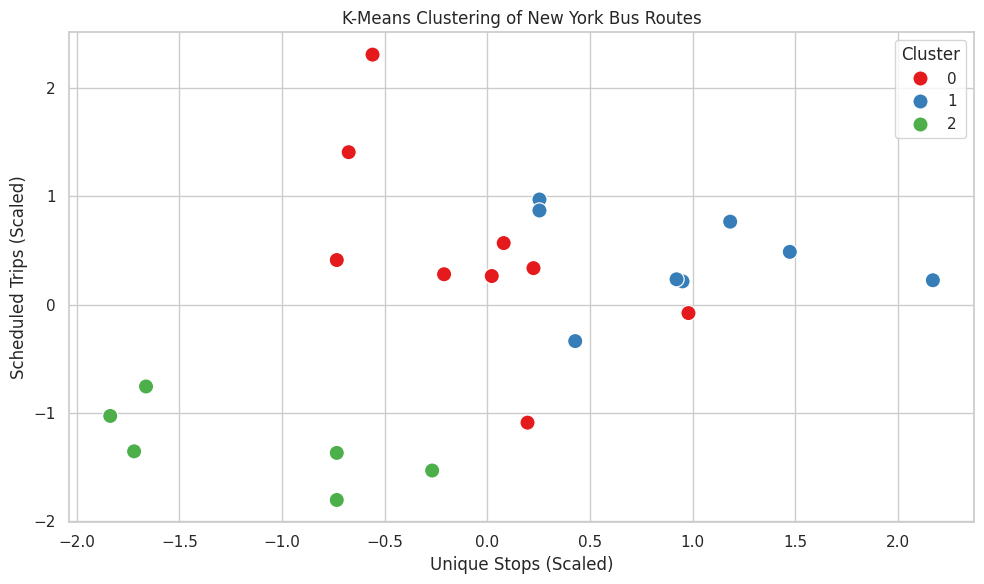

In [14]:
# Visualize K-Means clusters

cluster_df = X_train.copy()

cluster_df["Cluster"] = train_clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_df,
    x="unique_stops",
    y="total_scheduled_trips",
    hue="Cluster",
    palette="Set1",
    s=120
)

plt.title("K-Means Clustering of New York Bus Routes")
plt.xlabel("Unique Stops (Scaled)")
plt.ylabel("Scheduled Trips (Scaled)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 11. DBSCAN Clustering

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is an unsupervised machine-learning algorithm that groups data points based on their density.

Unlike K-Means, DBSCAN does not require the number of clusters to be specified in advance. It identifies dense groups of similar data points and marks isolated points as noise.

In RouteRanker, DBSCAN is applied to the scaled route-level features to identify groups of routes with similar scheduled service characteristics.

In [15]:
# Train the DBSCAN clustering model

dbscan = DBSCAN(
    eps=1.5,
    min_samples=3
)

dbscan_clusters = dbscan.fit_predict(X_train)

print("DBSCAN Model Trained Successfully!")

print("\nDBSCAN Cluster Distribution:")
print(pd.Series(dbscan_clusters).value_counts().sort_index())

print("\nNumber of Clusters (excluding noise):",
      len(set(dbscan_clusters)) - (1 if -1 in dbscan_clusters else 0))

print("Number of Noise Points:",
      list(dbscan_clusters).count(-1))

DBSCAN Model Trained Successfully!

DBSCAN Cluster Distribution:
0    20
1     3
Name: count, dtype: int64

Number of Clusters (excluding noise): 2
Number of Noise Points: 0


## 12. DBSCAN Cluster Visualization

This section visualizes the clusters identified by the DBSCAN algorithm. A scatter plot is used to compare routes based on their scaled number of unique stops and scheduled trips.

The visualization helps us understand how DBSCAN groups routes according to feature density.

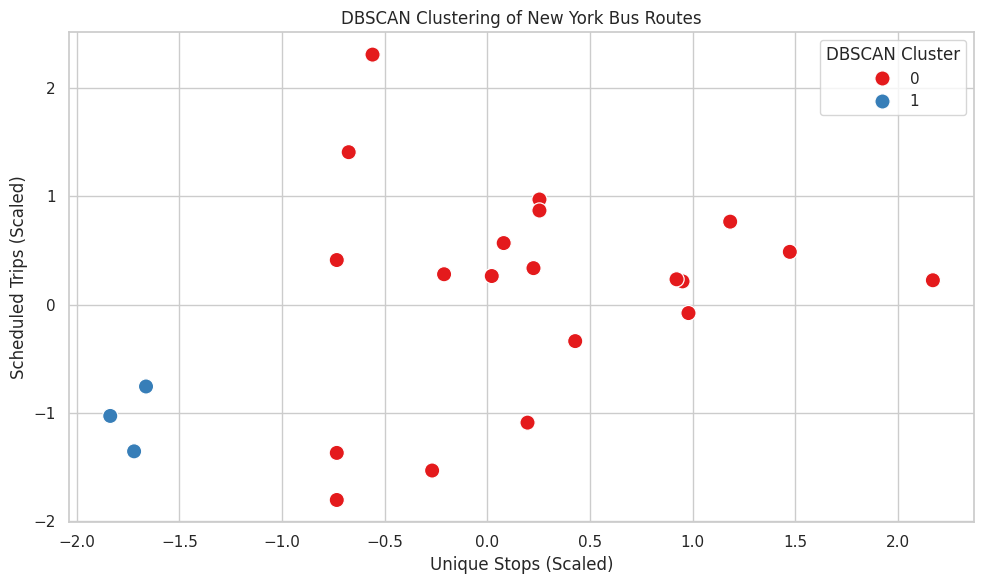

In [16]:
dbscan_df = X_train.copy()
dbscan_df["Cluster"] = dbscan_clusters.astype(str)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=dbscan_df,
    x="unique_stops",
    y="total_scheduled_trips",
    hue="Cluster",
    palette="Set1",
    s=120
)

plt.title("DBSCAN Clustering of New York Bus Routes")
plt.xlabel("Unique Stops (Scaled)")
plt.ylabel("Scheduled Trips (Scaled)")
plt.legend(title="DBSCAN Cluster")
plt.tight_layout()
plt.show()

## 13. Comparison of K-Means and DBSCAN

This section compares the clustering results obtained using K-Means and DBSCAN.

K-Means divides the routes into a predefined number of clusters, whereas DBSCAN identifies clusters based on data density.

The comparison helps us understand how both algorithms group New York bus routes using the selected service-related features.

In [17]:
comparison_df = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Number of Clusters": [
        len(set(train_clusters)),
        len(set(dbscan_clusters)) - (1 if -1 in dbscan_clusters else 0)
    ],
    "Noise Points": [
        0,
        list(dbscan_clusters).count(-1)
    ]
})

print("Clustering Algorithm Comparison")
display(comparison_df)

Clustering Algorithm Comparison


,Algorithm,Number of Clusters,Noise Points
0,K-Means,3,0
1,DBSCAN,2,0


## 14. DBSCAN Model Evaluation

This section evaluates the quality of DBSCAN clustering using standard clustering evaluation metrics.

The following metrics are used:

1. **Silhouette Score:** Measures how well-separated the clusters are. A higher score indicates better separation.
2. **Davies-Bouldin Index:** Measures similarity between clusters. A lower score indicates better clustering.
3. **Calinski-Harabasz Score:** Measures the ratio of between-cluster dispersion to within-cluster dispersion. A higher score generally indicates better-defined clusters.

These metrics help compare DBSCAN with K-Means.

In [18]:
if len(set(dbscan_clusters)) > 1 and -1 not in dbscan_clusters:

    dbscan_silhouette = silhouette_score(X_train, dbscan_clusters)
    dbscan_db_index = davies_bouldin_score(X_train, dbscan_clusters)
    dbscan_ch_score = calinski_harabasz_score(X_train, dbscan_clusters)

    print("DBSCAN Evaluation Results")
    print("-------------------------")
    print("Silhouette Score:", round(dbscan_silhouette, 4))
    print("Davies-Bouldin Index:", round(dbscan_db_index, 4))
    print("Calinski-Harabasz Score:", round(dbscan_ch_score, 4))

else:
    print("DBSCAN evaluation metrics cannot be reliably calculated.")
    print("The model must identify at least two clusters without noise points.")

DBSCAN Evaluation Results
-------------------------
Silhouette Score: 0.4369
Davies-Bouldin Index: 0.483
Calinski-Harabasz Score: 12.6139


## 15. Classification Model Preparation

Random Forest is a supervised machine learning algorithm used for classification and prediction.

For this project, Random Forest can be used to classify bus route performance based on route characteristics and passenger ridership information.

However, the current GTFS dataset contains scheduled service features rather than actual passenger-demand labels. Therefore, a valid classification model requires real ridership data and properly defined performance categories.

This section identifies the data required before classification model training.

## 16. Requirements for Classification Model

To build a reliable classification model, the following information is required:

1. Actual passenger ridership for each bus route.
2. Route-level ridership patterns during different time periods.
3. Suitable input features combining scheduled service and passenger demand.
4. Clearly defined performance categories based on a documented method.
5. Training and validation datasets with corresponding labels.

The MTA Bus Hourly Ridership dataset will be used as the passenger-demand source.

**Important:** Scheduled trips alone cannot determine whether a route is balanced or overcrowded. These categories will only be created after analyzing actual ridership data and defining appropriate criteria.

## 17. MTA Bus Hourly Ridership Data Collection

This section connects to the official New York MTA Bus Hourly Ridership dataset through its public API.

The dataset provides estimated passenger ridership information for bus routes, including timestamps, route identifiers, payment categories, and transfers.

A limited sample will be retrieved initially to inspect the dataset structure and verify the available fields before further processing.

In [19]:
import requests
import pandas as pd

api_url = "https://data.ny.gov/resource/gxb3-akrn.json"

params = {
    "$select": "transit_timestamp,bus_route,ridership,transfers",
    "$limit": 1000,
    "$order": "transit_timestamp DESC"
}

response = requests.get(api_url, params=params, timeout=60)

print("API Status Code:", response.status_code)

response.raise_for_status()

ridership_df = pd.DataFrame(response.json())

print("Retrieved Rows:", len(ridership_df))
print("\nDataset Preview:")
display(ridership_df.head())

print("\nDataset Information:")
ridership_df.info()

API Status Code: 200
Retrieved Rows: 1000

Dataset Preview:


,transit_timestamp,bus_route,ridership,transfers
0,2026-11-10T23:00:00.000,Q108,0,0
1,2026-11-10T23:00:00.000,M99,0,0
2,2026-11-10T23:00:00.000,Q1,0,0
3,2026-11-10T23:00:00.000,Q103,0,0
4,2026-11-10T23:00:00.000,Q109,0,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   transit_timestamp  1000 non-null   object
 1   bus_route          1000 non-null   object
 2   ridership          1000 non-null   object
 3   transfers          1000 non-null   object
dtypes: object(4)
memory usage: 31.4+ KB


## 18. Data Cleaning and Preprocessing

This section prepares the collected MTA ridership data for analysis.

The preprocessing steps include:

1. Checking missing values.
2. Removing duplicate records.
3. Converting timestamps into datetime format.
4. Converting ridership and transfer values into numeric format.
5. Checking the cleaned dataset.

These steps improve data quality before performing ridership analysis.

In [20]:
# Create a working copy
ridership_clean = ridership_df.copy()

# Check missing values
print("Missing Values Before Cleaning:")
print(ridership_clean.isnull().sum())

# Remove duplicate records
ridership_clean = ridership_clean.drop_duplicates()

# Convert timestamp
ridership_clean["transit_timestamp"] = pd.to_datetime(
    ridership_clean["transit_timestamp"],
    errors="coerce"
)

# Convert numeric columns
for col in ["ridership", "transfers"]:
    ridership_clean[col] = pd.to_numeric(
        ridership_clean[col],
        errors="coerce"
    )

# Remove records missing essential information
ridership_clean = ridership_clean.dropna(
    subset=["transit_timestamp", "bus_route", "ridership"]
)

print("\nCleaned Dataset Shape:", ridership_clean.shape)

print("\nMissing Values After Cleaning:")
print(ridership_clean.isnull().sum())

print("\nCleaned Dataset Preview:")
display(ridership_clean.head())

Missing Values Before Cleaning:
transit_timestamp    0
bus_route            0
ridership            0
transfers            0
dtype: int64

Cleaned Dataset Shape: (433, 4)

Missing Values After Cleaning:
transit_timestamp    0
bus_route            0
ridership            0
transfers            0
dtype: int64

Cleaned Dataset Preview:


,transit_timestamp,bus_route,ridership,transfers
0,2026-11-10 23:00:00,Q108,0,0
1,2026-11-10 23:00:00,M99,0,0
2,2026-11-10 23:00:00,Q1,0,0
3,2026-11-10 23:00:00,Q103,0,0
4,2026-11-10 23:00:00,Q109,0,0


## 19. Hourly Ridership Analysis

This section analyzes passenger ridership across different hours of the day.

The timestamp is used to extract the hour, and passenger ridership is aggregated by hour.

A line chart is generated to identify periods with relatively high and low passenger demand.

This analysis helps understand daily passenger-demand patterns across the retrieved MTA records.

Hourly Ridership Summary:


,hour,ridership
0,23,1214


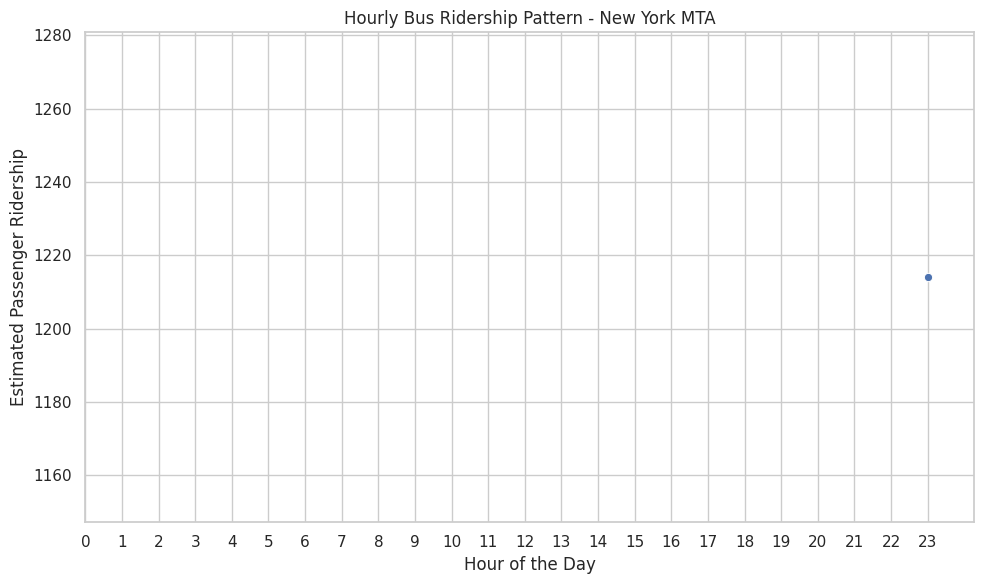

In [21]:
# Extract hour from timestamp
ridership_clean["hour"] = (
    ridership_clean["transit_timestamp"].dt.hour
)

# Calculate total ridership for each hour
hourly_ridership = (
    ridership_clean.groupby("hour")["ridership"]
    .sum()
    .reset_index()
)

print("Hourly Ridership Summary:")
display(hourly_ridership)

# Visualize hourly ridership
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=hourly_ridership,
    x="hour",
    y="ridership",
    marker="o"
)

plt.title("Hourly Bus Ridership Pattern - New York MTA")
plt.xlabel("Hour of the Day")
plt.ylabel("Estimated Passenger Ridership")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

## 20. Peak and Off-Peak Ridership Identification

This section identifies peak and off-peak passenger-demand periods using hourly ridership totals.

- Peak hour: The hour with the highest estimated passenger ridership.
- Off-peak hour: The hour with the lowest estimated passenger ridership.

This analysis helps identify periods of higher and lower passenger demand in the collected sample.

In [22]:
peak_hour = hourly_ridership.loc[
    hourly_ridership["ridership"].idxmax()
]

off_peak_hour = hourly_ridership.loc[
    hourly_ridership["ridership"].idxmin()
]

print("Peak Ridership Hour:")
print("Hour:", int(peak_hour["hour"]))
print("Estimated Ridership:", peak_hour["ridership"])

print("\nOff-Peak Ridership Hour:")
print("Hour:", int(off_peak_hour["hour"]))
print("Estimated Ridership:", off_peak_hour["ridership"])

Peak Ridership Hour:
Hour: 23
Estimated Ridership: 1214

Off-Peak Ridership Hour:
Hour: 23
Estimated Ridership: 1214


## 21. Route-wise Ridership Analysis

This section analyzes estimated passenger ridership for individual bus routes.

The ridership records are grouped by bus route, and the total estimated passenger ridership is calculated for each route.

A bar chart is used to compare passenger demand across the routes in the collected sample.

This analysis helps identify routes with relatively higher and lower estimated passenger demand.

Route-wise Ridership Summary:


,bus_route,ridership
162,Q32,117
9,B38,101
103,M60+,92
13,B44,90
112,M96,83
105,M7,66
295,SIM33C,54
187,Q55,50
193,Q64,46
185,Q53+,44


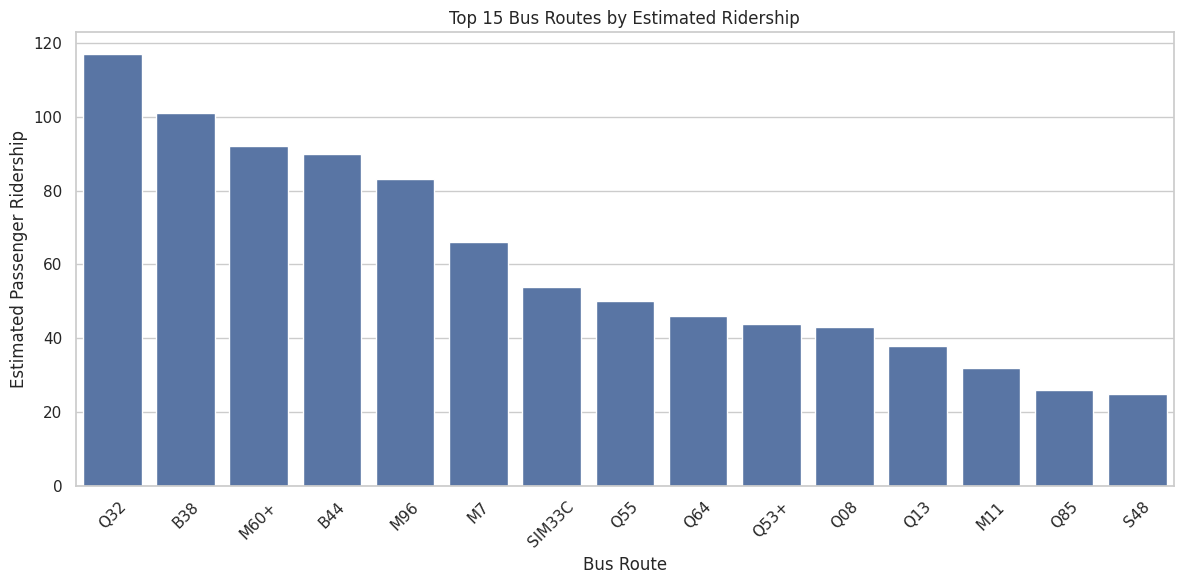

In [23]:
# Calculate total ridership for each bus route
route_ridership = (
    ridership_clean.groupby("bus_route")["ridership"]
    .sum()
    .reset_index()
    .sort_values(by="ridership", ascending=False)
)

print("Route-wise Ridership Summary:")
display(route_ridership.head(15))

# Visualize the top 15 routes
top_routes = route_ridership.head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_routes,
    x="bus_route",
    y="ridership"
)

plt.title("Top 15 Bus Routes by Estimated Ridership")
plt.xlabel("Bus Route")
plt.ylabel("Estimated Passenger Ridership")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 22. Ridership Distribution Analysis

This section examines the distribution of passenger ridership values in the collected MTA dataset.

A histogram is used to understand how frequently different ridership levels occur. This helps identify the spread of passenger demand across the retrieved records.

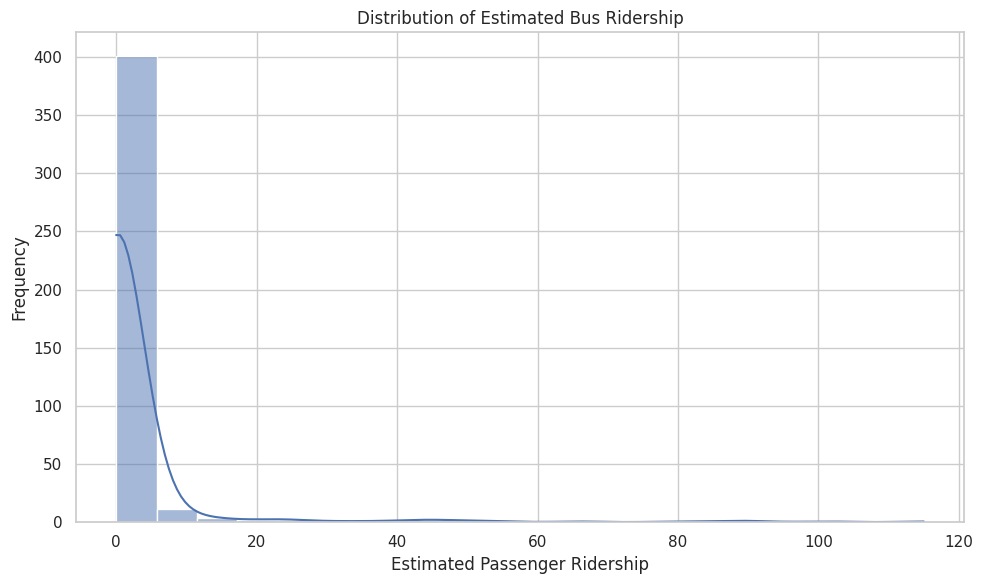

In [24]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ridership_clean,
    x="ridership",
    bins=20,
    kde=True
)

plt.title("Distribution of Estimated Bus Ridership")
plt.xlabel("Estimated Passenger Ridership")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 23. Route-Level Ridership Feature Engineering

This section creates route-level passenger-demand features from the collected MTA ridership records.

The following features will be calculated:

1. Total estimated ridership per route.
2. Average estimated ridership per record.
3. Number of ridership records per route.

These features will be combined with the previously prepared GTFS route-level features to create a dataset for further model development.

Note: The current API sample is limited to 1,000 records and does not represent complete daily or annual ridership.

In [25]:
# Aggregate ridership information by route
ridership_features = (
    ridership_clean.groupby("bus_route")
    .agg(
        total_estimated_ridership=("ridership", "sum"),
        average_estimated_ridership=("ridership", "mean"),
        ridership_record_count=("ridership", "count")
    )
    .reset_index()
)

print("Route-Level Ridership Features:")
display(ridership_features.head())

print("Number of Routes:", len(ridership_features))

Route-Level Ridership Features:


,bus_route,total_estimated_ridership,average_estimated_ridership,ridership_record_count
0,B102,0,0.0,1
1,B106,0,0.0,1
2,B111,0,0.0,1
3,B12,0,0.0,1
4,B25,0,0.0,1


Number of Routes: 362


## 24. Integration of GTFS and Ridership Features

This section integrates the GTFS route-level dataset with the MTA ridership feature dataset.

The GTFS dataset provides scheduled service characteristics, while the ridership dataset provides estimated passenger-demand information.

The datasets are merged using their route identifiers. This creates a combined dataset for further analysis and model development.

Only matching route identifiers will be included in the initial merged dataset.

In [30]:
print("GTFS Route IDs:")
print(gtfs_features["route_id"].head(20).tolist())

print("\nMTA Ridership Route Names:")
print(ridership_features["bus_route"].head(20).tolist())

print("\nGTFS Route Short Names:")
print(gtfs_features["route_short_name"].head(20).tolist())

GTFS Route IDs:
['1', '2', '3', '4', '5', '6', '6X', '7', '7X', 'A', 'B', 'C', 'D', 'E', 'F', 'FS', 'FX', 'G', 'GS', 'H']

MTA Ridership Route Names:
['B102', 'B106', 'B111', 'B12', 'B25', 'B3', 'B31', 'B32', 'B35', 'B38', 'B41', 'B42', 'B43', 'B44', 'B45', 'B46', 'B48', 'B49', 'B6', 'B60']

GTFS Route Short Names:
['1', '2', '3', '4', '5', '6', '6X', '7', '7X', 'A', 'B', 'C', 'D', 'E', 'F', 'S', 'FX', 'G', 'S', 'S']


## 26. GTFS Route Type Analysis

This section examines the transport types available in the GTFS dataset.

The purpose is to identify bus routes and distinguish them from subway and other transport services before integrating the ridership data.

In [32]:
print("Available Route Types:")
print(gtfs_features["route_type"].value_counts())

print("\nRoute Type and Short Name:")
display(
    gtfs_features[
        ["route_id", "route_short_name", "route_long_name", "route_type"]
    ].head(30)
)

Available Route Types:
route_type
1    28
2     1
Name: count, dtype: int64

Route Type and Short Name:


,route_id,route_short_name,route_long_name,route_type
0,1,1,Broadway - 7 Avenue Local,1
1,2,2,7 Avenue Express,1
2,3,3,7 Avenue Express,1
3,4,4,Lexington Avenue Express,1
4,5,5,Lexington Avenue Express,1
5,6,6,Lexington Avenue Local,1
6,6X,6X,Pelham Bay Park Express,1
7,7,7,Flushing Local,1
8,7X,7X,Flushing Express,1
9,A,A,8 Avenue Express,1


## 27. Collect New York MTA Bus GTFS Data

The previously collected GTFS feed primarily contained subway services.

This section collects a bus-specific GTFS feed so that bus route identifiers can be compared with the MTA bus ridership dataset.

The new feed will be inspected before integration.

In [33]:
import requests
import zipfile
import io

bus_gtfs_url = "https://www.mta.info/developers"

response = requests.get(bus_gtfs_url, timeout=60)

print("MTA Website Status:", response.status_code)

MTA Website Status: 200


In [34]:
bus_gtfs_url = "https://rrgtfsfeeds.s3.amazonaws.com/gtfs_busco.zip"

bus_response = requests.get(bus_gtfs_url, timeout=120)

print("Bus GTFS Status:", bus_response.status_code)
print("Downloaded Size (MB):",
      round(len(bus_response.content) / (1024 * 1024), 2))

if bus_response.status_code == 200:
    bus_zip = zipfile.ZipFile(io.BytesIO(bus_response.content))
    print("\nGTFS Files:")
    print(bus_zip.namelist()[:15])

Bus GTFS Status: 200
Downloaded Size (MB): 8.06

GTFS Files:
['agency.txt', 'calendar.txt', 'calendar_dates.txt', 'routes.txt', 'shapes.txt', 'stop_times.txt', 'stops.txt', 'trips.txt', 'feed_info.txt']


## 28. Bus GTFS Data Inspection

This section loads the routes, trips, stops, and stop-time information from the newly downloaded MTA Bus Company GTFS feed.

The route information will be inspected to identify available bus routes and verify their route types before integrating passenger ridership data.

In [35]:
bus_routes = pd.read_csv(
    bus_zip.open("routes.txt")
)

bus_trips = pd.read_csv(
    bus_zip.open("trips.txt")
)

bus_stops = pd.read_csv(
    bus_zip.open("stops.txt")
)

bus_stop_times = pd.read_csv(
    bus_zip.open("stop_times.txt")
)

print("Bus Routes Shape:", bus_routes.shape)
print("Bus Trips Shape:", bus_trips.shape)
print("Bus Stops Shape:", bus_stops.shape)
print("Bus Stop Times Shape:", bus_stop_times.shape)

print("\nRoute Type Distribution:")
print(bus_routes["route_type"].value_counts())

print("\nBus Route Preview:")
display(
    bus_routes[
        ["route_id", "route_short_name", "route_long_name", "route_type"]
    ].head(15)
)

Bus Routes Shape: (92, 9)
Bus Trips Shape: (45424, 7)
Bus Stops Shape: (2758, 5)
Bus Stop Times Shape: (1077998, 8)

Route Type Distribution:
route_type
3    92
Name: count, dtype: int64

Bus Route Preview:


,route_id,route_short_name,route_long_name,route_type
0,Q06,Q6,Jamaica - Sutphin Blvd - Jfk Cargo Area,3
1,Q07,Q7,Cypress Hills - Rockaway Blvd - Jfk Travel Plz.,3
2,Q08,Q8,Gateway Mall / East Ny - Jamaica,3
3,Q09,Q9,Jamaica - South Ozone Park,3
4,Q10,Q10,Jfk Airtrain - Kew Gardens Via Rockaway,3
5,Q11,Q11,Howard Beach - Elmhurst,3
6,Q18,Q18,Astoria - Maspeth,3
7,Q19,Q19,Flushing - Astoria,3
8,Q22,Q22,Rockaway Beach Bl / Beach Channel Dr,3
9,Q23,Q23,East Elmhurst - Forest Hills,3


## 29. Bus Route Identifier Matching

This section compares route names from the MTA Bus Company GTFS feed with route names from the MTA ridership dataset.

Matching route identifiers are required to combine scheduled service information with passenger-demand information.

In [36]:
# Normalize route names
bus_routes["route_short_name"] = (
    bus_routes["route_short_name"]
    .astype(str).str.strip().str.upper()
)

ridership_features["bus_route"] = (
    ridership_features["bus_route"]
    .astype(str).str.strip().str.upper()
)

# Find matching route names
gtfs_route_names = set(bus_routes["route_short_name"])
ridership_route_names = set(ridership_features["bus_route"])

matching_routes = sorted(
    gtfs_route_names.intersection(ridership_route_names)
)

print("GTFS Bus Routes:", len(gtfs_route_names))
print("Ridership Routes:", len(ridership_route_names))
print("Matching Routes:", len(matching_routes))

print("\nMatching Route Names:")
print(matching_routes)

GTFS Bus Routes: 92
Ridership Routes: 362
Matching Routes: 74

Matching Route Names:
['BM1', 'BM4', 'BXM11', 'BXM18', 'BXM3', 'BXM6', 'BXM7', 'BXM8', 'BXM9', 'Q10', 'Q100', 'Q101', 'Q102', 'Q103', 'Q104', 'Q11', 'Q110', 'Q111', 'Q112', 'Q113', 'Q114', 'Q115', 'Q18', 'Q19', 'Q22', 'Q23', 'Q25', 'Q26', 'Q28', 'Q32', 'Q33', 'Q35', 'Q37', 'Q40', 'Q41', 'Q47', 'Q49', 'Q50', 'Q51', 'Q60', 'Q64', 'Q65', 'Q66', 'Q69', 'Q72', 'Q74', 'Q80', 'QM1', 'QM10', 'QM11', 'QM12', 'QM15', 'QM16', 'QM17', 'QM18', 'QM2', 'QM20', 'QM21', 'QM24', 'QM25', 'QM31', 'QM32', 'QM34', 'QM35', 'QM36', 'QM4', 'QM40', 'QM42', 'QM44', 'QM5', 'QM6', 'QM65', 'QM7', 'QM8']


## 30. Integration of Bus GTFS and Ridership Data

This section combines the MTA Bus Company GTFS route information with the passenger ridership features.

The datasets are merged using the matching public bus route names.

The resulting dataset contains both scheduled service characteristics and estimated passenger-demand features.

In [37]:
# Prepare GTFS route features
bus_gtfs_features = bus_routes[
    ["route_id", "route_short_name", "route_long_name", "route_type"]
].copy()

# Merge using public route names
combined_bus_df = pd.merge(
    bus_gtfs_features,
    ridership_features,
    left_on="route_short_name",
    right_on="bus_route",
    how="inner"
)

print("Combined Bus Dataset Shape:", combined_bus_df.shape)

print("\nCombined Dataset Preview:")
display(combined_bus_df.head())

print("\nNumber of Matched Routes:",
      combined_bus_df["route_short_name"].nunique())

Combined Bus Dataset Shape: (74, 8)

Combined Dataset Preview:


,route_id,route_short_name,route_long_name,route_type,bus_route,total_estimated_ridership,average_estimated_ridership,ridership_record_count
0,Q10,Q10,Jfk Airtrain - Kew Gardens Via Rockaway,3,Q10,9,4.5,2
1,Q11,Q11,Howard Beach - Elmhurst,3,Q11,0,0.0,1
2,Q18,Q18,Astoria - Maspeth,3,Q18,0,0.0,1
3,Q19,Q19,Flushing - Astoria,3,Q19,0,0.0,1
4,Q22,Q22,Rockaway Beach Bl / Beach Channel Dr,3,Q22,1,0.5,2



Number of Matched Routes: 74


## 31. Combined Dataset Validation

This section checks the quality and completeness of the integrated dataset.

The validation process includes checking missing values, duplicate routes, and numerical feature summaries.

In [38]:
print("Dataset Shape:", combined_bus_df.shape)

print("\nMissing Values:")
print(combined_bus_df.isnull().sum())

print("\nDuplicate Route Names:",
      combined_bus_df["route_short_name"].duplicated().sum())

print("\nNumerical Feature Summary:")
display(
    combined_bus_df[
        [
            "total_estimated_ridership",
            "average_estimated_ridership",
            "ridership_record_count"
        ]
    ].describe()
)

Dataset Shape: (74, 8)

Missing Values:
route_id                       0
route_short_name               0
route_long_name                0
route_type                     0
bus_route                      0
total_estimated_ridership      0
average_estimated_ridership    0
ridership_record_count         0
dtype: int64

Duplicate Route Names: 0

Numerical Feature Summary:


,total_estimated_ridership,average_estimated_ridership,ridership_record_count
count,74.000000,74.000000,74.000000
mean,3.189189,1.423423,1.243243
std,14.645281,5.510623,0.518449
min,0.000000,0.000000,1.000000
25%,0.000000,0.000000,1.000000
50%,0.000000,0.000000,1.000000
75%,0.000000,0.000000,1.000000
max,117.000000,39.000000,3.000000


## 32. Combined Dataset Visualization

This section visualizes the sample-based estimated ridership across the matched bus routes.

A bar chart is used to identify routes with higher estimated ridership within the retrieved sample.

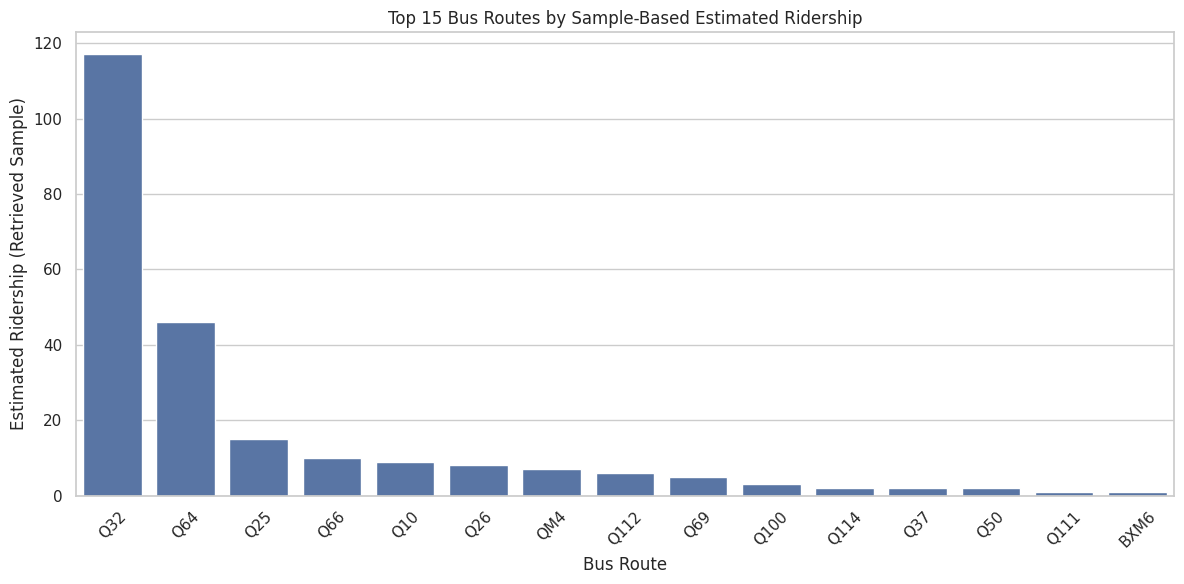

In [39]:
top_routes = combined_bus_df.sort_values(
    by="total_estimated_ridership",
    ascending=False
).head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_routes,
    x="route_short_name",
    y="total_estimated_ridership"
)

plt.title("Top 15 Bus Routes by Sample-Based Estimated Ridership")
plt.xlabel("Bus Route")
plt.ylabel("Estimated Ridership (Retrieved Sample)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 33. Average Ridership Analysis by Route

This section compares the average estimated ridership across different bus routes.

The analysis helps identify routes with higher average ridership in the retrieved sample.

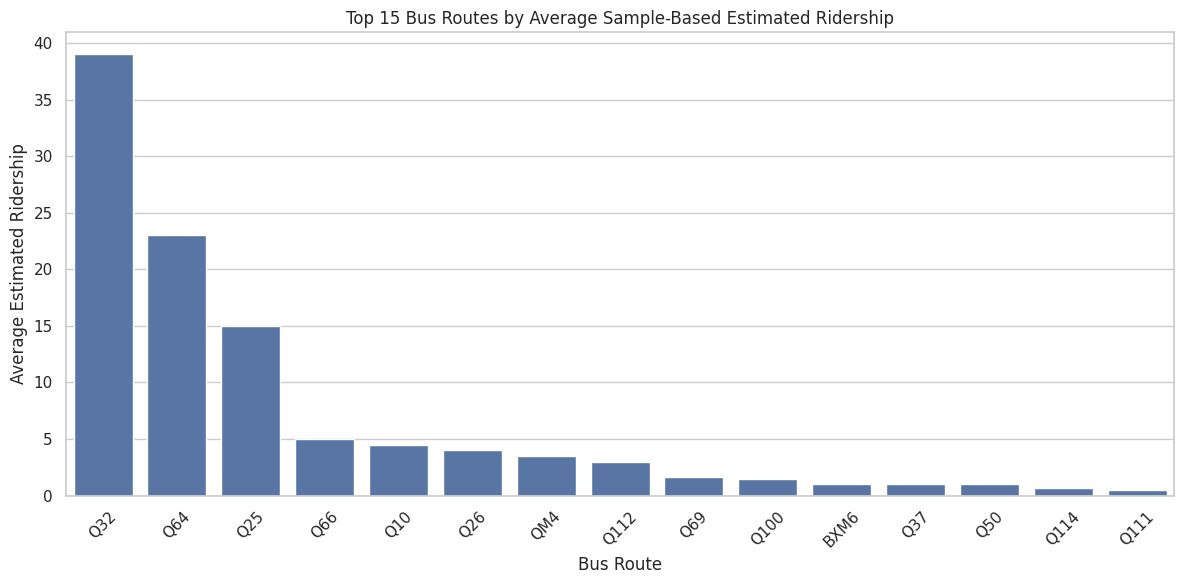

In [40]:
top_average_routes = combined_bus_df.sort_values(
    by="average_estimated_ridership",
    ascending=False
).head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_average_routes,
    x="route_short_name",
    y="average_estimated_ridership"
)

plt.title("Top 15 Bus Routes by Average Sample-Based Estimated Ridership")
plt.xlabel("Bus Route")
plt.ylabel("Average Estimated Ridership")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 34. Export Combined Bus Dataset

This section exports the integrated dataset containing bus route information and sample-based estimated ridership features for future analysis and model development.

In [42]:
combined_bus_df.to_csv(
    "new_york_combined_bus_ridership.csv",
    index=False
)

print("Combined dataset exported successfully!")
print("File: new_york_combined_bus_ridership.csv")

Combined dataset exported successfully!
File: new_york_combined_bus_ridership.csv


from google.colab import files

files.download("new_york_combined_bus_ridership.csv")

In [43]:
from google.colab import files

files.download("new_york_combined_bus_ridership.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 35. Classification Model Preparation

Classification models are used to predict route performance categories.

The available dataset contains route information and sample-based estimated ridership features. However, it does not contain verified route performance labels such as balanced or overcrowded.

Therefore, this section examines the available features and identifies the requirements for reliable classification model development.

In [44]:
print("Classification Dataset Overview")
print("---------------------------------")

print("Dataset Shape:", combined_bus_df.shape)

print("\nAvailable Features:")
print(combined_bus_df.columns.tolist())

print("\nTarget Label Availability:")
target_labels = ["balanced", "overcrowded"]

print("Verified performance labels available:", False)
print("Classification model training requires verified target labels.")

Classification Dataset Overview
---------------------------------
Dataset Shape: (74, 8)

Available Features:
['route_id', 'route_short_name', 'route_long_name', 'route_type', 'bus_route', 'total_estimated_ridership', 'average_estimated_ridership', 'ridership_record_count']

Target Label Availability:
Verified performance labels available: False
Classification model training requires verified target labels.


### Interpretation

The combined dataset contains 74 bus routes and 8 features. However, verified target labels for route performance classification are unavailable.

Therefore, supervised classification models such as Random Forest and XGBoost cannot be reliably trained or evaluated using the current dataset.

The project will proceed with clustering-based analysis and inference to identify groups of routes with similar characteristics.

## 36. K-Means Inference on Bus Routes

This section applies the trained K-Means model to the available bus route features.

The model assigns each route to a cluster based on similarities in its feature values.

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select bus ridership features
bus_model_features = combined_bus_df[
    [
        "total_estimated_ridership",
        "average_estimated_ridership",
        "ridership_record_count"
    ]
].copy()

# Handle any missing or infinite values
bus_model_features = bus_model_features.replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

# Create a new scaler for bus ridership features
bus_scaler = StandardScaler()

bus_model_scaled = bus_scaler.fit_transform(
    bus_model_features
)

# Train a separate K-Means model for bus routes
bus_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

bus_route_clusters = bus_kmeans.fit_predict(
    bus_model_scaled
)

# Add cluster assignments to dataset
combined_bus_df["bus_route_cluster"] = bus_route_clusters

print("Bus Route Clustering Completed!")
print("\nCluster Distribution:")
print(combined_bus_df["bus_route_cluster"].value_counts().sort_index())

display(
    combined_bus_df[
        ["route_short_name", "average_estimated_ridership", "bus_route_cluster"]
    ].head(10)
)

Bus Route Clustering Completed!

Cluster Distribution:
bus_route_cluster
0    59
1     1
2    14
Name: count, dtype: int64


,route_short_name,average_estimated_ridership,bus_route_cluster
0,Q10,4.5,2
1,Q11,0.0,0
2,Q18,0.0,0
3,Q19,0.0,0
4,Q22,0.5,2
5,Q23,0.0,0
6,Q25,15.0,0
7,Q26,4.0,2
8,Q28,0.0,0
9,Q32,39.0,1


## 37. Bus Route Cluster Visualization

This section visualizes the clusters generated by the K-Means algorithm.

The scatter plot compares total estimated ridership with average estimated ridership for the matched bus routes.

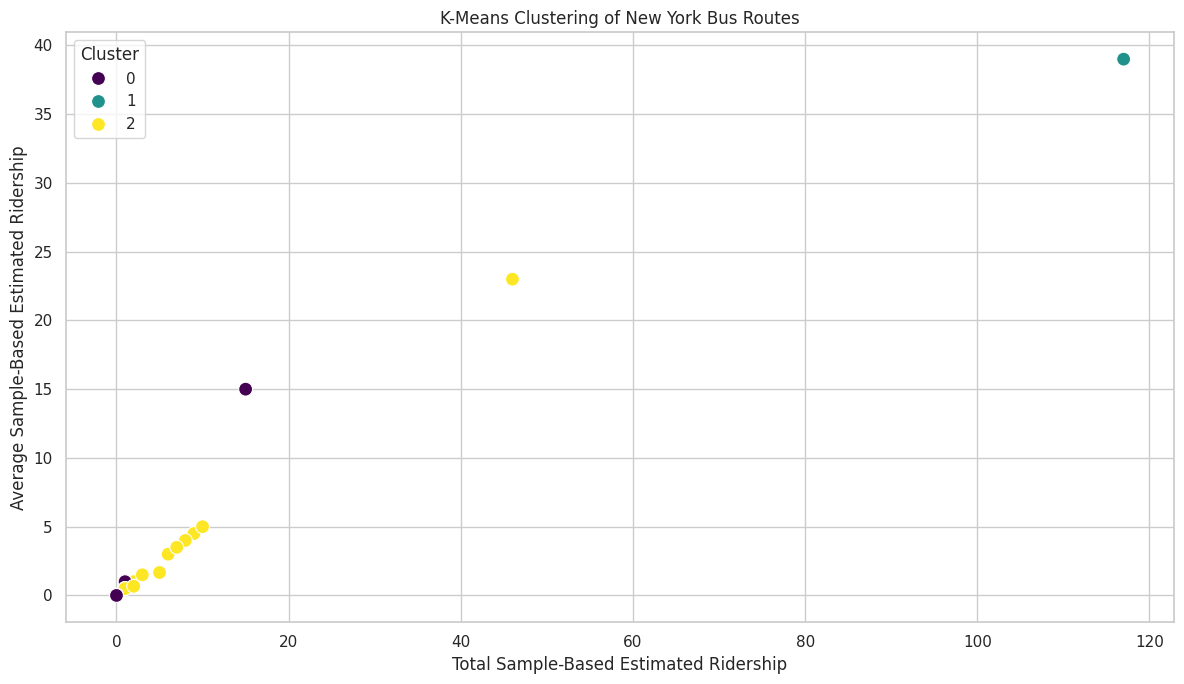

In [47]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=combined_bus_df,
    x="total_estimated_ridership",
    y="average_estimated_ridership",
    hue="bus_route_cluster",
    palette="viridis",
    s=100
)

plt.title("K-Means Clustering of New York Bus Routes")
plt.xlabel("Total Sample-Based Estimated Ridership")
plt.ylabel("Average Sample-Based Estimated Ridership")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 38. Cluster-wise Ridership Analysis

This section summarizes the ridership characteristics of each cluster.

The analysis helps compare the sample-based estimated ridership patterns across the groups identified by K-Means.

In [48]:
cluster_summary = combined_bus_df.groupby(
    "bus_route_cluster"
).agg(
    number_of_routes=("route_short_name", "count"),
    average_ridership=("average_estimated_ridership", "mean"),
    total_sample_ridership=("total_estimated_ridership", "sum"),
    average_record_count=("ridership_record_count", "mean")
).round(2)

display(cluster_summary)

,number_of_routes,average_ridership,total_sample_ridership,average_record_count
bus_route_cluster,,,,
0,59,0.27,16,1.00
1,1,39.00,117,3.00
2,14,3.60,103,2.14


### Interpretation

The cluster-wise analysis shows three different ridership patterns.

- Cluster 0 contains 59 routes with a low average sample-based estimated ridership of 0.27.
- Cluster 1 contains one route with the highest average of 39.00.
- Cluster 2 contains 14 routes with an average of 3.60.

Cluster 1 represents a route with a higher estimated ridership in the retrieved sample, while Cluster 0 contains most of the matched routes.

These results describe patterns in the limited API sample and should not be treated as complete route demand or actual passenger occupancy.

In [49]:
for cluster in sorted(combined_bus_df["bus_route_cluster"].unique()):
    print(f"\nCluster {cluster}")
    print("-" * 30)

    display(
        combined_bus_df[
            combined_bus_df["bus_route_cluster"] == cluster
        ][
            ["route_short_name", "average_estimated_ridership"]
        ].sort_values(
            by="average_estimated_ridership",
            ascending=False
        )
    )


Cluster 0
------------------------------


,route_short_name,average_estimated_ridership
6,Q25,15.0
32,BXM6,1.0
2,Q18,0.0
3,Q19,0.0
5,Q23,0.0
8,Q28,0.0
10,Q33,0.0
11,Q35,0.0
13,Q40,0.0
14,Q41,0.0



Cluster 1
------------------------------


,route_short_name,average_estimated_ridership
9,Q32,39.0



Cluster 2
------------------------------


,route_short_name,average_estimated_ridership
20,Q64,23.000000
22,Q66,5.000000
0,Q10,4.500000
7,Q26,4.000000
65,QM4,3.500000
43,Q112,3.000000
23,Q69,1.666667
36,Q100,1.500000
12,Q37,1.000000
17,Q50,1.000000


## 40. Route Optimization Suggestions

This section generates preliminary route optimization suggestions based on the clustering results.

The suggestions use sample-based estimated ridership patterns to identify routes that may require further investigation.

The recommendations are preliminary and require validation using complete ridership and operational data.

In [50]:
def generate_route_suggestion(row):
    if row["bus_route_cluster"] == 1:
        return "Review service capacity using complete ridership data"
    elif row["bus_route_cluster"] == 2:
        return "Monitor ridership patterns for service planning"
    else:
        return "Review service coverage and collect more ridership data"

combined_bus_df["optimization_suggestion"] = (
    combined_bus_df.apply(generate_route_suggestion, axis=1)
)

display(
    combined_bus_df[
        [
            "route_short_name",
            "average_estimated_ridership",
            "bus_route_cluster",
            "optimization_suggestion"
        ]
    ].head(15)
)

,route_short_name,average_estimated_ridership,bus_route_cluster,optimization_suggestion
0,Q10,4.5,2,Monitor ridership patterns for service planning
1,Q11,0.0,0,Review service coverage and collect more rider...
2,Q18,0.0,0,Review service coverage and collect more rider...
3,Q19,0.0,0,Review service coverage and collect more rider...
4,Q22,0.5,2,Monitor ridership patterns for service planning
5,Q23,0.0,0,Review service coverage and collect more rider...
6,Q25,15.0,0,Review service coverage and collect more rider...
7,Q26,4.0,2,Monitor ridership patterns for service planning
8,Q28,0.0,0,Review service coverage and collect more rider...
9,Q32,39.0,1,Review service capacity using complete ridersh...


## 41. Export Final Route Optimization Results

This section exports the bus route clustering results and preliminary optimization suggestions into a CSV file for further analysis and project documentation.

In [51]:
combined_bus_df.to_csv(
    "new_york_route_optimization_results.csv",
    index=False
)

print("Final route optimization results exported successfully!")
print("Total routes:", len(combined_bus_df))
print("File: new_york_route_optimization_results.csv")

Final route optimization results exported successfully!
Total routes: 74
File: new_york_route_optimization_results.csv
